      eps  delta                            method            kind  either  point_above  nonlocal_  mean_loss_diff  worst_regret  auroc_gain
0   0.005  0.010                            Pooled  no certificate     5.2         68.8        NaN          0.0029        0.0245      0.0005
1   0.005  0.010                            Pooled       certified     0.0          0.0       17.0          0.0000        0.0012      0.0002
2   0.005  0.010                     AFL (floor 0)  no certificate    79.2        117.4        NaN          0.0201        0.0780     -0.0565
3   0.005  0.010                     AFL (floor 0)       certified     0.0          0.0        1.0          0.0000        0.0009     -0.0000
4   0.005  0.010                   AFL (floor 0.5)  no certificate    27.4         95.2        NaN          0.0093        0.0346     -0.0322
5   0.005  0.010                   AFL (floor 0.5)       certified     0.0          0.0        7.4          0.0001        0.0017     -0.0002
6   0.005  0.

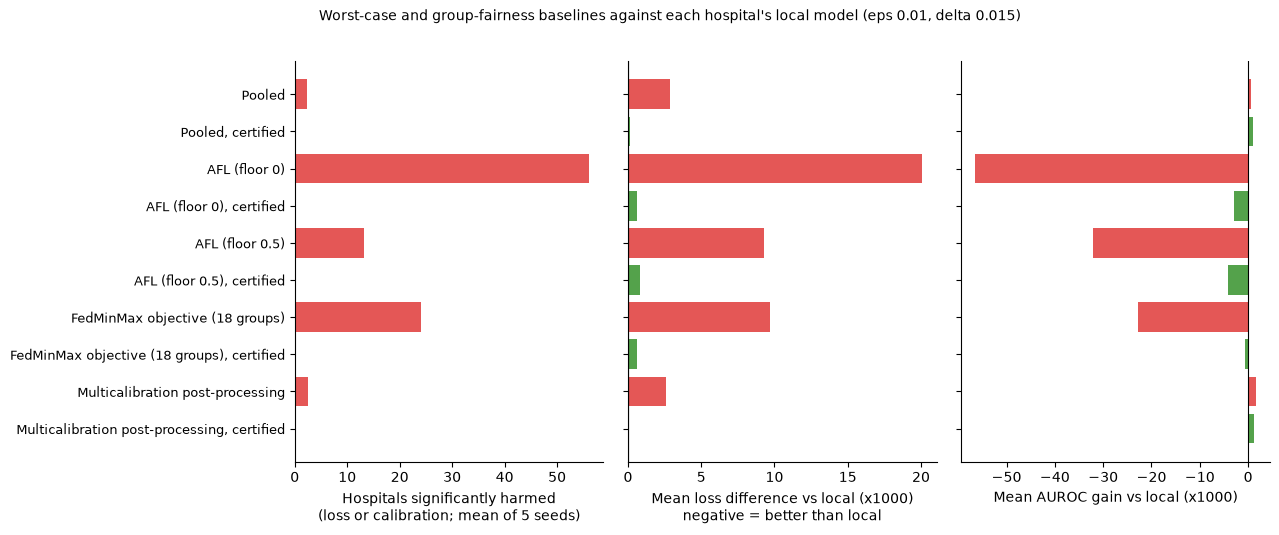

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.multitest import multipletests
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
seeds = [110, 111, 112, 113, 114]; HEAD = [(0.005, 0.01), (0.01, 0.015), (0.02, 0.02)]
D = {s: pd.read_csv(f"../outputs/tables/more_baselines_seed{s}.csv").copy() for s in seeds}
SRC = ["pool", "afl0", "afl0.5", "fedminmax", "multicalib"]
NAME = {"pool": "Pooled", "afl0": "AFL (floor 0)", "afl0.5": "AFL (floor 0.5)",
        "fedminmax": "FedMinMax objective (18 groups)", "multicalib": "Multicalibration post-processing"}

def lm(r, pre, eps):
    d, se = r[f"{pre}__diff"].values, r[f"{pre}__se"].values
    z = np.where(se > 0, (d - eps) / np.where(se > 0, se, 1), -np.inf)
    return multipletests(1 - stats.norm.cdf(z), alpha=0.05, method="holm")[0]

rows = []
for eps, delta in HEAD:
    for src in SRC:
        for kind, pre in [("no certificate", src), ("certified", f"cert_{src}_e{eps}_d{delta}")]:
            out = []
            for s in seeds:
                r = D[s]; l = lm(r, pre, eps); c = r[f"{pre}__gaplb"].values > delta
                out.append(dict(either=(l | c).sum(), point_above=(r[f"{pre}__gapmax"] > delta).sum(),
                                nonlocal_=(r[f"{pre}__blend"] > 0).sum() if "cert" in pre else np.nan,
                                mean_loss_diff=r[f"{pre}__diff"].mean(), worst_regret=r[f"{pre}__diff"].max(),
                                auroc_gain=(r[f"{pre}__auroc"] - r["local__auroc"]).mean()))
            rows.append({"eps": eps, "delta": delta, "method": NAME[src], "kind": kind, **pd.DataFrame(out).mean().to_dict()})
T = pd.DataFrame(rows); T.to_csv("../outputs/tables/T_more_baselines.csv", index=False); print(T.round(4).to_string())

t = T[(T.eps == 0.01) & (T.delta == 0.015)].reset_index(drop=True)
t["label"] = t.method + np.where(t.kind == "certified", ", certified", "")
col = np.where(t.kind == "certified", "#54A24B", "#E45756")
yy = np.arange(len(t))[::-1]
fig, ax = plt.subplots(1, 3, figsize=(15, 5.2), sharey=True)
ax[0].barh(yy, t.either, color=col); ax[0].set_xlabel("Hospitals significantly harmed\n(loss or calibration; mean of 5 seeds)")
ax[1].barh(yy, 1000 * t.mean_loss_diff, color=col); ax[1].axvline(0, c="k", lw=0.8); ax[1].set_xlabel("Mean loss difference vs local (x1000)\nnegative = better than local")
ax[2].barh(yy, 1000 * t.auroc_gain, color=col); ax[2].axvline(0, c="k", lw=0.8); ax[2].set_xlabel("Mean AUROC gain vs local (x1000)")
ax[0].set_yticks(yy); ax[0].set_yticklabels(t.label, fontsize=9)
fig.suptitle("Worst-case and group-fairness baselines against each hospital's local model (eps 0.01, delta 0.015)", fontsize=10)
plt.subplots_adjust(wspace=0.08, left=0.25)
plt.savefig("../outputs/figures/fig25_more_baselines.png", dpi=300); plt.savefig("../outputs/figures/fig25_more_baselines.pdf"); plt.show()

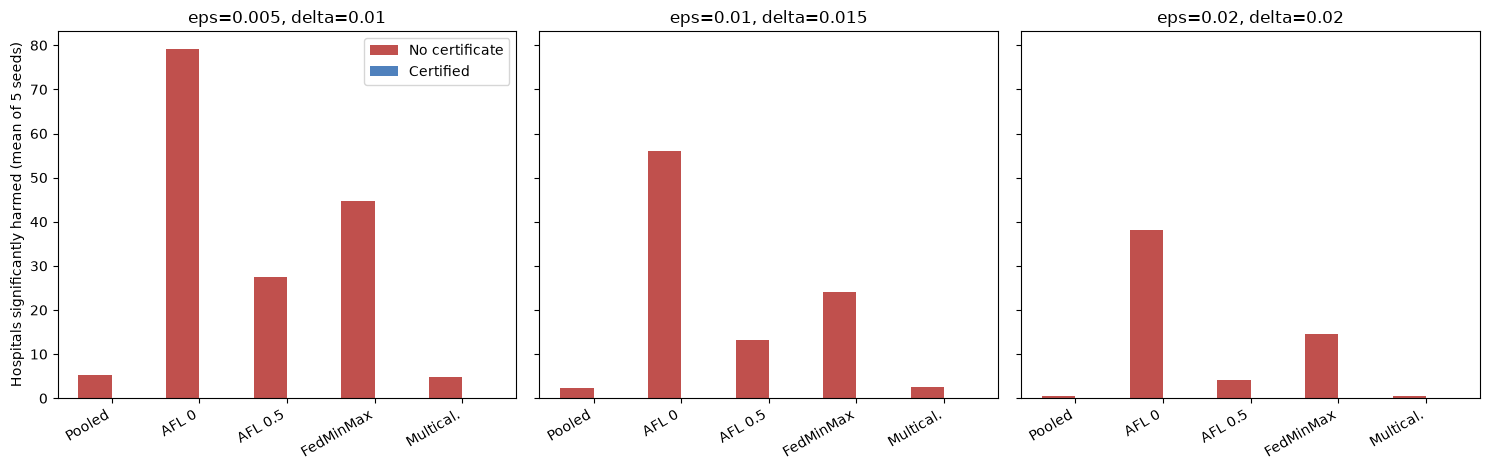

tivity,T19_apr_sensitivity
table,Table24,loho,T_loho
table,Table25,icu2012,T18_icu2012
table,Table26,icu2012_by_unit,T18b_icu2012_by_unit
table,Table27,icu_diagnostic,T_icu_diagnostic
table,Table28,price_of_no_harm_grid,F12_price_of_no_harm_grid
table,Table29,software_settings,T21_software_settings



In [1]:
import pandas as pd, matplotlib.pyplot as plt, numpy as np, shutil, os
root = r"C:\noharm-fl"
src = os.path.join(root, "outputs", "tables", "T_more_baselines.csv")
df = pd.read_csv(src)
os.makedirs(os.path.join(root, "paper", "assets", "tables"), exist_ok=True)
os.makedirs(os.path.join(root, "paper", "assets", "figures"), exist_ok=True)
shutil.copy(src, os.path.join(root, "paper", "assets", "tables", "Table30_more_baselines.csv"))

methods = list(dict.fromkeys(df["method"]))
pairs = sorted(df[["eps", "delta"]].drop_duplicates().itertuples(index=False))
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True)
x = np.arange(len(methods)); w = 0.38
for ax, (e, d) in zip(axes, pairs):
    s = df[(df.eps == e) & (df.delta == d)]
    u = [s[(s.method == m) & (s.kind == "no certificate")]["either"].iloc[0] for m in methods]
    c = [s[(s.method == m) & (s.kind == "certified")]["either"].iloc[0] for m in methods]
    ax.bar(x - w/2, u, w, label="No certificate", color="#c0504d")
    ax.bar(x + w/2, c, w, label="Certified", color="#4f81bd")
    ax.set_title(f"eps={e}, delta={d}")
    ax.set_xticks(x); ax.set_xticklabels(["Pooled", "AFL 0", "AFL 0.5", "FedMinMax", "Multical."], rotation=30, ha="right")
axes[0].set_ylabel("Hospitals significantly harmed (mean of 5 seeds)")
axes[0].legend()
plt.tight_layout()
out = os.path.join(root, "paper", "assets", "figures", "Fig25_more_baselines.png")
plt.savefig(out, dpi=300); plt.savefig(out.replace(".png", ".pdf")); plt.show()
print(open(os.path.join(root, "paper", "assets", "MANIFEST.csv")).read()[-300:])

In [2]:
import pandas as pd, os
root = r"C:\noharm-fl"
mp = os.path.join(root, "paper", "assets", "MANIFEST.csv")
m = pd.read_csv(mp, header=None)
print(m.head(3).to_string())   # shows the column order
print(m[m[1].astype(str).isin(["Table30", "Fig25", "Figure25"])])

        0      1            2                 3
0    type  label         name       source_file
1  figure  Fig01       design       fig1_design
2  figure  Fig02  cohort_flow  fig2_cohort_flow
         0      1        2              3
25  figure  Fig25  icu2012  fig17_icu2012


In [3]:
import os, shutil, pandas as pd
root = r"C:\noharm-fl"
fa = os.path.join(root, "paper", "assets", "figures")
for ext in (".png", ".pdf"):
    old = os.path.join(fa, "Fig25_more_baselines" + ext)
    new = os.path.join(fa, "Fig26_more_baselines" + ext)
    if os.path.exists(old):
        os.replace(old, new)
    shutil.copy(new, os.path.join(root, "outputs", "figures", "fig26_more_baselines" + ext))

mp = os.path.join(root, "paper", "assets", "MANIFEST.csv")
m = pd.read_csv(mp)
new_rows = pd.DataFrame([
    {"type": "figure", "label": "Fig26", "name": "more_baselines", "source_file": "fig26_more_baselines"},
    {"type": "table",  "label": "Table30", "name": "more_baselines", "source_file": "T_more_baselines"},
])
m = pd.concat([m, new_rows], ignore_index=True).drop_duplicates(subset=["type", "label"])
m.to_csv(mp, index=False)
print(m.tail(4).to_string()); print(m.type.value_counts())
print(sorted(os.listdir(fa))[-4:])

      type    label                   name                source_file
52   table  Table28  price_of_no_harm_grid  F12_price_of_no_harm_grid
53   table  Table29      software_settings      T21_software_settings
54  figure    Fig26         more_baselines       fig26_more_baselines
55   table  Table30         more_baselines           T_more_baselines
type
table     30
figure    26
Name: count, dtype: int64
['Fig25_icu2012.pdf', 'Fig25_icu2012.png', 'Fig26_more_baselines.pdf', 'Fig26_more_baselines.png']


In [4]:
import pandas as pd, numpy as np, os, shutil
root = r"C:\noharm-fl"
HEAD = [(0.005, 0.01), (0.01, 0.015), (0.02, 0.02)]
rows = []
for s in range(110, 115):
    r = pd.read_csv(os.path.join(root, "outputs", "tables", f"c3_primal_dual_seed{s}.csv"))
    for e, d in HEAD:
        pdk = f"pd_e{e}"
        n_pd = int((r[f"cert_{pdk}_e{e}_d{d}__blend"] > 0).sum())
        n_p0 = int((r[f"cert_pool80_e{e}_d{d}__blend"] > 0).sum())
        rows.append(dict(seed=s, eps=e, delta=d, certified_pd=n_pd, certified_pool80=n_p0, gain=n_pd - n_p0,
                         auroc_cost=float((r["pool80__auroc"] - r[f"{pdk}__auroc"]).mean())))
t = pd.DataFrame(rows)
summ = t.groupby(["eps", "delta"]).agg(certified_pd=("certified_pd", "mean"), certified_pool80=("certified_pool80", "mean"),
        gain_mean=("gain", "mean"), gain_min=("gain", "min"), gain_max=("gain", "max"),
        auroc_cost=("auroc_cost", "mean")).round(4).reset_index()
summ["rule_met"] = summ["gain_mean"] >= 5
print(summ.to_string())
out = os.path.join(root, "outputs", "tables", "T_c3_primal_dual.csv")
summ.to_csv(out, index=False)
shutil.copy(out, os.path.join(root, "paper", "assets", "tables", "Table31_c3_primal_dual.csv"))
mp = os.path.join(root, "paper", "assets", "MANIFEST.csv")
m = pd.read_csv(mp)
m = pd.concat([m, pd.DataFrame([{"type": "table", "label": "Table31", "name": "c3_primal_dual", "source_file": "T_c3_primal_dual"}])],
              ignore_index=True).drop_duplicates(subset=["type", "label"])
m.to_csv(mp, index=False); print(m.type.value_counts())

     eps  delta  certified_pd  certified_pool80  gain_mean  gain_min  gain_max  auroc_cost  rule_met
0  0.005  0.010          16.4              17.2       -0.8        -2         0      0.0003     False
1  0.010  0.015          55.8              55.8        0.0         0         0      0.0004     False
2  0.020  0.020          99.4              99.6       -0.2        -1         0      0.0000     False
type
table     31
figure    26
Name: count, dtype: int64


In [5]:
import pandas as pd, numpy as np, os, shutil
from scipy import stats
from statsmodels.stats.multitest import multipletests
root = r"C:\noharm-fl"; tabs = os.path.join(root, "outputs", "tables")
HEAD = [(0.005, 0.01), (0.01, 0.015), (0.02, 0.02)]
SEEDS = [s for s in range(115, 125) if os.path.exists(os.path.join(tabs, f"cert_full_seed{s}.csv"))]
print("seeds found:", SEEDS)

def loss_mask(diff, se, eps):
    z = np.where(se > 0, (diff - eps) / np.where(se > 0, se, 1), -np.inf)
    return multipletests(1 - stats.norm.cdf(z), alpha=0.05, method="holm")[0]

rows, R = [], {}
for s in SEEDS:
    r = pd.read_csv(os.path.join(tabs, f"cert_full_seed{s}.csv")); R[s] = r
    for e, d in HEAD:
        for label, pre, eps_, del_ in [("pooled (unclipped), harm at pair", "pool_full", e, d),
                                       ("pooled (unclipped), zero tolerance", "pool_full", 0.0, 0.0),
                                       ("certified pooled", f"cert_pool_e{e}_d{d}", e, d),
                                       ("certified fine-tuned", f"cert_ft_e{e}_d{d}", e, d)]:
            lm = loss_mask(r[f"{pre}__diff"].values, r[f"{pre}__se"].values, eps_)
            cm = r[f"{pre}__gaplb"].values > del_
            rows.append(dict(seed=s, eps=e, delta=d, method=label, loss_harm=int(lm.sum()), cal_harm=int(cm.sum()),
                             either=int((lm | cm).sum()),
                             nonlocal_=int((r[f"{pre}__blend"] > 0).sum()) if pre.startswith("cert") else np.nan,
                             mean_loss_diff=r[f"{pre}__diff"].mean(),
                             auroc_gain=(r[f"{pre}__auroc"] - r["local__auroc"]).mean()))
per = pd.DataFrame(rows)
per.to_csv(os.path.join(tabs, "fresh_seeds_per_seed.csv"), index=False)
agg = per.groupby(["eps", "delta", "method"]).agg(loss_harm_max=("loss_harm", "max"), cal_harm_max=("cal_harm", "max"),
        either_mean=("either", "mean"), either_max=("either", "max"), nonlocal_mean=("nonlocal_", "mean"),
        mean_loss_diff=("mean_loss_diff", "mean"), auroc_gain=("auroc_gain", "mean")).round(5).reset_index()

# bootstrap over hospitals (hospital means over seeds)
rng = np.random.default_rng(2026)
ci = []
for e, d in HEAD:
    for lab, pre in [("certified pooled", f"cert_pool_e{e}_d{d}"), ("certified fine-tuned", f"cert_ft_e{e}_d{d}")]:
        dl = pd.concat([R[s].set_index("hospital")[f"{pre}__diff"] for s in SEEDS], axis=1).dropna().mean(axis=1)
        au = pd.concat([(R[s][f"{pre}__auroc"] - R[s]["local__auroc"]).set_axis(R[s]["hospital"]) for s in SEEDS], axis=1).dropna().mean(axis=1)
        bd = [rng.choice(dl.values, len(dl)).mean() for _ in range(2000)]
        ba = [rng.choice(au.values, len(au)).mean() for _ in range(2000)]
        ci.append(dict(eps=e, delta=d, method=lab, loss_diff=dl.mean(), loss_lo=np.percentile(bd, 2.5), loss_hi=np.percentile(bd, 97.5),
                       auroc=au.mean(), auroc_lo=np.percentile(ba, 2.5), auroc_hi=np.percentile(ba, 97.5)))
ci = pd.DataFrame(ci).round(5)
out = agg.merge(ci, on=["eps", "delta", "method"], how="left")
print(out.to_string())
cert = per[per.method.str.startswith("certified")]
n_dec = len(cert) // 1 * 0 + int(len(SEEDS) * len(HEAD) * 2 * len(R[SEEDS[0]]))
print(f"\nCertified harmed hospital-decisions: {int(cert.either.sum())} of {n_dec}; rule-of-three 95% upper bound {3 / n_dec:.4%} (if 0)")
op = os.path.join(tabs, "T_fresh_seeds.csv"); out.to_csv(op, index=False)
shutil.copy(op, os.path.join(root, "paper", "assets", "tables", "Table32_fresh_seeds.csv"))
mp = os.path.join(root, "paper", "assets", "MANIFEST.csv"); m = pd.read_csv(mp)
m = pd.concat([m, pd.DataFrame([{"type": "table", "label": "Table32", "name": "fresh_seeds", "source_file": "T_fresh_seeds"}])],
              ignore_index=True).drop_duplicates(subset=["type", "label"]); m.to_csv(mp, index=False)

seeds found: [115, 116, 117, 118, 119, 120, 121, 122, 123, 124]
      eps  delta                              method  loss_harm_max  cal_harm_max  either_mean  either_max  nonlocal_mean  mean_loss_diff  auroc_gain  loss_diff  loss_lo  loss_hi    auroc  auroc_lo  auroc_hi
0   0.005  0.010                certified fine-tuned              0             0          0.0           0           17.5        -0.00002     0.00012   -0.00002 -0.00004  0.00000  0.00012  -0.00001   0.00025
1   0.005  0.010                    certified pooled              0             0          0.0           0           16.5         0.00001     0.00024    0.00001 -0.00002  0.00005  0.00024   0.00002   0.00049
2   0.005  0.010    pooled (unclipped), harm at pair              2             8          6.1           8            NaN         0.00272     0.00124        NaN      NaN      NaN      NaN       NaN       NaN
3   0.005  0.010  pooled (unclipped), zero tolerance             22            25         27.9          